# nanoGPT `model.py` — interactive tutorial (SOLUTIONS)

**Goal:** understand every line of `model.py` well enough to write it yourself from a blank file.

How this notebook works
* 🔎 **Explore** cells run real code and show the numbers. Change things and re-run.
* 🛠 **Your turn** cells contain a stub with `TODO`s. Fill it in, then run the ✅ **check** cell below it, which compares *your* module with the real `model.py` (same weights in, outputs must match).
* 🧪 **Experiment** cells train small models live on the GPU so you can *see* what each technique buys.
* Predict first, then run. Each experiment has a "Predict" prompt; write your guess down before looking.
* This is the **solutions** notebook: every exercise is already filled in (and verified to pass).

The model we study: a char-level GPT (6 layers, 6 heads, 384 dims, context 256, 10.7M params) trained on Shakespeare. Full write-up of the 40 experiments we ran: `README.md`.

In [1]:
import sys, os, math, json, time
sys.path.insert(0, os.getcwd()); sys.path.insert(0, os.path.join(os.getcwd(), '..'))
import numpy as np, torch, torch.nn as nn
from torch.nn import functional as F
import matplotlib.pyplot as plt
import ipywidgets as W
from IPython.display import display

import lab, nbhelpers
from nbhelpers import check, load_ref_weights, close
from model import GPT, GPTConfig, LayerNorm, CausalSelfAttention, MLP, Block      # the REAL nanoGPT, our reference
torch.set_printoptions(precision=3, linewidth=140, sci_mode=False)
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': .3})
device = lab.DEV
print('device:', device, torch.cuda.get_device_name(0) if device == 'cuda' else '')
print(lab.ensure_data())                         # builds the Shakespeare dataset on first use (needs PyPI access only)
model_ref, meta = lab.ensure_checkpoint()       # trains the reference model once (~95 s) if there is no checkpoint
print('reference model loaded, params:', model_ref.get_num_params() / 1e6, 'M')

device: cuda NVIDIA A100-SXM4-80GB
data ready


reference model loaded, params: 10.679808 M


## 1. Data: text → ids → (input, target)

A language model is trained to predict the **next token**. For a window of text `x` the target `y` is `x` shifted left by one, and a window of length T gives **T training examples at once** (position t predicts token t+1).

In [2]:
ddir = lab.DATA_DIR
train_data = np.memmap(os.path.join(ddir, 'train.bin'), dtype=np.uint16, mode='r')
val_data = np.memmap(os.path.join(ddir, 'val.bin'), dtype=np.uint16, mode='r')
print(f'train {len(train_data):,} tokens, val {len(val_data):,} tokens, vocab {len(meta["itos"])}')

def get_batch(split, batch_size, block_size, device=device):
    d = train_data if split == 'train' else val_data
    ix = torch.randint(len(d) - block_size - 1, (batch_size,))
    x = torch.stack([torch.from_numpy(d[i:i + block_size].astype(np.int64)) for i in ix])
    y = torch.stack([torch.from_numpy(d[i + 1:i + 1 + block_size].astype(np.int64)) for i in ix])
    return x.to(device), y.to(device)

x, y = get_batch('train', 2, 12)
for b in range(2):
    print('x:', repr(lab.decode(meta, x[b].tolist())))
    print('y:', repr(lab.decode(meta, y[b].tolist())), '  <- same text shifted by one')
print()
for t in range(5):
    print(f'context {lab.decode(meta, x[0, :t+1].tolist())!r:10} -> target {lab.decode(meta, [y[0, t].item()])!r}')

train 4,551,515 tokens, val 505,724 tokens, vocab 84
x: 'cess begs al'
y: 'ess begs all'   <- same text shifted by one
x: 'houldst do t'
y: 'ouldst do th'   <- same text shifted by one

context 'c'        -> target 'e'
context 'ce'       -> target 's'
context 'ces'      -> target 's'
context 'cess'     -> target ' '
context 'cess '    -> target 'b'


**Why is initial loss ≈ ln(vocab)?** With near-zero logits the model predicts a uniform distribution, so the cross-entropy is `ln(84) = 4.43`. Always check this at step 0, it catches many bugs.

In [3]:
print('ln(vocab) =', math.log(len(meta['itos'])))

ln(vocab) = 4.430816798843313


## 2. Embeddings: *what* the token is + *where* it is

`tok_emb = wte(idx)` → `(B, T, C)` and `pos_emb = wpe(arange(T))` → `(T, C)`, then they are **added**. Attention does not know order by itself, so without `wpe` the model sees a bag of characters (ablation: +0.26 val loss).

In [4]:
cfg_s = GPTConfig(block_size=8, vocab_size=len(meta['itos']), n_layer=2, n_head=2, n_embd=8, dropout=0.0, bias=False)
small = GPT(cfg_s).eval()
idx = torch.tensor([lab.encode(meta, 'to be, o')])
tok = small.transformer.wte(idx); pos = small.transformer.wpe(torch.arange(idx.size(1)))
print('idx', tuple(idx.shape), '| tok_emb', tuple(tok.shape), '| pos_emb', tuple(pos.shape))
sp = [i for i, c in enumerate('to be, o') if c == ' ']
print(f"space at t={sp}: same token vector? {torch.equal(tok[0, sp[0]], tok[0, sp[1]])} | same position vector? {torch.equal(pos[sp[0]], pos[sp[1]])}")

number of parameters: 0.00M
idx (1, 8) | tok_emb (1, 8, 8) | pos_emb (8, 8)
space at t=[2, 6]: same token vector? True | same position vector? False


## 3. LayerNorm

Per token: subtract the mean over the `C` features, divide by the std, then apply a learned gain (and optional bias). It keeps activations at a stable scale so deep stacks train. nanoGPT uses **pre-norm** (`x + f(ln(x))`).

In [5]:
v = torch.randn(2, 4, 8) * 5 + 3
o = LayerNorm(8, bias=False)(v)
print('before: mean %.2f std %.2f' % (v.mean(-1)[0, 0], v.std(-1, unbiased=False)[0, 0]))
print('after : mean %.2f std %.2f' % (o.mean(-1)[0, 0], o.std(-1, unbiased=False)[0, 0]))

before: mean 1.91 std 2.79
after : mean 0.00 std 1.00


### 🛠 Your turn 1 — LayerNorm

In [6]:

class MyLayerNorm(nn.Module):
    """LayerNorm with optional bias, written WITHOUT F.layer_norm."""
    def __init__(self, ndim, bias):
        super().__init__()
        self.weight = nn.Parameter(torch.ones(ndim))
        self.bias = nn.Parameter(torch.zeros(ndim)) if bias else None

    def forward(self, x):
        mean = x.mean(-1, keepdim=True)
        var = x.var(-1, keepdim=True, unbiased=False)
        y = (x - mean) / torch.sqrt(var + 1e-5) * self.weight
        return y + self.bias if self.bias is not None else y


In [7]:
def test_ln():
    for bias in (True, False):
        ref, mine = LayerNorm(16, bias), MyLayerNorm(16, bias)
        with torch.no_grad():
            ref.weight.normal_(1, .3)
            if bias: ref.bias.normal_()
        load_ref_weights(mine, ref)
        x = torch.randn(3, 5, 16) * 4 + 2
        close(mine(x), ref(x), f'bias={bias}')
check('MyLayerNorm matches model.LayerNorm', test_ln)

✅ MyLayerNorm matches model.LayerNorm


## 4. Causal self-attention — the core idea

For each token, build a **query** ("what am I looking for?"), a **key** ("what do I contain?") and a **value** ("what do I hand over if chosen?"). Score = `q·k/√head_size`; positions in the future are masked to −inf; `softmax` turns scores into weights that sum to 1; the output is the weighted sum of values.

```
x (B,T,C) --c_attn--> q,k,v (B,T,C) --split heads--> (B,nh,T,hs)
scores = q @ k^T / sqrt(hs)      (B,nh,T,T)
scores[future] = -inf ; w = softmax(scores) ; y = w @ v     (B,nh,T,hs)
y -> merge heads (B,T,C) --c_proj--> out
```
Run the cell, then change `T`, the seed, or comment out the mask line and see what changes.

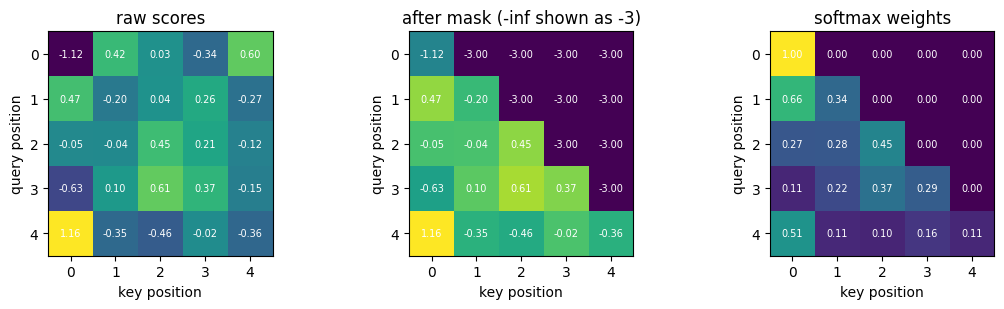

row sums: tensor([1.000, 1.000, 1.000, 1.000, 1.000], grad_fn=<SumBackward1>)


In [8]:
torch.manual_seed(1)
T_, C_, nh_ = 5, 8, 2
hs_ = C_ // nh_
xin = torch.randn(1, T_, C_)
c_attn = nn.Linear(C_, 3 * C_, bias=False)
q, k, v = c_attn(xin).split(C_, dim=2)
q, k, v = [t.view(1, T_, nh_, hs_).transpose(1, 2) for t in (q, k, v)]
scores = q @ k.transpose(-2, -1) / math.sqrt(hs_)
mask = torch.tril(torch.ones(T_, T_)).bool()
w = F.softmax(scores.masked_fill(~mask, float('-inf')), dim=-1)            # <- try removing the masked_fill
fig, ax = plt.subplots(1, 3, figsize=(11, 3.2))
for a, M, t in zip(ax, (scores[0, 0].detach(), scores.masked_fill(~mask, float('-inf'))[0, 0].detach().clamp(min=-3), w[0, 0].detach()), ('raw scores', 'after mask (-inf shown as -3)', 'softmax weights')):
    im = a.imshow(M, cmap='viridis'); a.set_title(t); a.set_xlabel('key position'); a.set_ylabel('query position'); a.grid(False)
    for i in range(T_):
        for j in range(T_): a.text(j, i, f'{M[i, j]:.2f}', ha='center', va='center', color='w', fontsize=7)
plt.tight_layout(); plt.show()
print('row sums:', w[0, 0].sum(-1))

**Why `/ sqrt(head_size)`?** `q·k` is a sum of `hs` products, so its std grows like `√hs`. Large scores → saturated softmax → tiny gradients. Check the numbers:

In [9]:
for hs in (4, 16, 64, 256):
    qq, kk = torch.randn(20000, hs), torch.randn(20000, hs)
    s = (qq * kk).sum(-1)
    print(f'hs={hs:4d}  std(q.k) = {s.std():6.2f}   scaled: {(s / math.sqrt(hs)).std():.2f}   softmax max-prob of 8 random scores: {F.softmax((torch.randn(1000, 8) * s.std()), -1).max(-1).values.mean():.2f} (unscaled) vs {F.softmax(torch.randn(1000, 8), -1).max(-1).values.mean():.2f} (scaled)')

hs=   4  std(q.k) =   2.00   scaled: 1.00   softmax max-prob of 8 random scores: 0.56 (unscaled) vs 0.36 (scaled)
hs=  16  std(q.k) =   3.99   scaled: 1.00   softmax max-prob of 8 random scores: 0.75 (unscaled) vs 0.35 (scaled)
hs=  64  std(q.k) =   7.97   scaled: 1.00   softmax max-prob of 8 random scores: 0.88 (unscaled) vs 0.36 (scaled)
hs= 256  std(q.k) =  16.00   scaled: 1.00   softmax max-prob of 8 random scores: 0.94 (unscaled) vs 0.36 (scaled)


### 🔎 Explore: attention maps of the trained model
Pick a layer and head and type some text. Look for heads that attend to the *previous* character, to the *start of the word*, to *punctuation / newline*, or just to themselves.

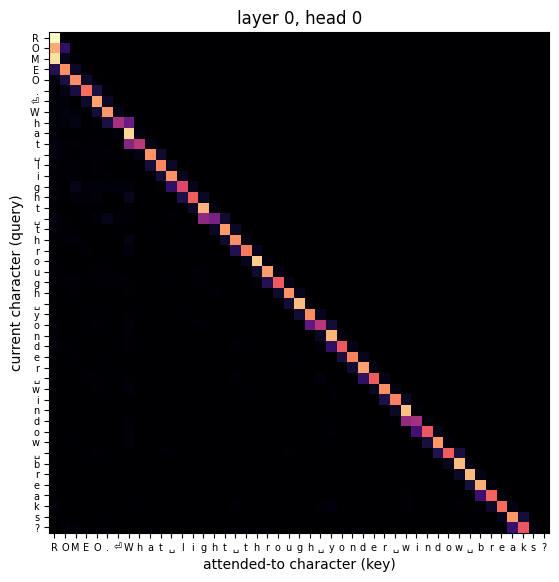

In [10]:
def show_attention(text='ROMEO.\nWhat light through yonder window breaks?', layer=0, head=0):
    ids = torch.tensor([lab.encode(meta, text)[-model_ref.config.block_size:]], device=device)
    maps = lab.attention_maps(model_ref, ids)
    A = maps[layer][head]
    chars = [lab.decode(meta, [i]).replace('\n', '⏎').replace(' ', '␣') for i in ids[0].tolist()]
    fig, ax = plt.subplots(figsize=(7.5, 6.5))
    ax.imshow(A, cmap='magma'); ax.grid(False)
    ax.set_xticks(range(len(chars))); ax.set_xticklabels(chars, fontsize=7); ax.set_yticks(range(len(chars))); ax.set_yticklabels(chars, fontsize=7)
    ax.set_xlabel('attended-to character (key)'); ax.set_ylabel('current character (query)'); ax.set_title(f'layer {layer}, head {head}')
    plt.show()
show_attention()

In [11]:
W.interact(show_attention, text=W.Text(value='ROMEO.\nWhat light through yonder window breaks?', layout=W.Layout(width='500px')),
           layer=W.IntSlider(min=0, max=model_ref.config.n_layer - 1, value=0), head=W.IntSlider(min=0, max=model_ref.config.n_head - 1, value=0));

interactive(children=(Text(value='ROMEO.\nWhat light through yonder window breaks?', description='text', layou…

### 🛠 Your turn 2 — Causal self-attention
Write it **manually** (no `scaled_dot_product_attention`); then the checker also verifies that changing a *future* token never changes earlier outputs.

In [12]:

class MyCausalSelfAttention(nn.Module):
    def __init__(self, config):
        super().__init__()
        assert config.n_embd % config.n_head == 0
        self.c_attn = nn.Linear(config.n_embd, 3 * config.n_embd, bias=config.bias)
        self.c_proj = nn.Linear(config.n_embd, config.n_embd, bias=config.bias)
        self.attn_dropout = nn.Dropout(config.dropout)
        self.resid_dropout = nn.Dropout(config.dropout)
        self.n_head, self.n_embd = config.n_head, config.n_embd
        self.register_buffer('mask', torch.tril(torch.ones(config.block_size, config.block_size)), persistent=False)

    def forward(self, x):
        B, T, C = x.size()
        hs = C // self.n_head
        q, k, v = self.c_attn(x).split(C, dim=2)
        q = q.view(B, T, self.n_head, hs).transpose(1, 2)
        k = k.view(B, T, self.n_head, hs).transpose(1, 2)
        v = v.view(B, T, self.n_head, hs).transpose(1, 2)
        scores = (q @ k.transpose(-2, -1)) / math.sqrt(hs)
        scores = scores.masked_fill(self.mask[:T, :T] == 0, float('-inf'))
        w = self.attn_dropout(F.softmax(scores, dim=-1))
        y = (w @ v).transpose(1, 2).contiguous().view(B, T, C)
        return self.resid_dropout(self.c_proj(y))


In [13]:
cfg_t = GPTConfig(block_size=16, vocab_size=30, n_layer=2, n_head=2, n_embd=16, dropout=0.0, bias=True)

def test_attn():
    ref, mine = CausalSelfAttention(cfg_t).eval(), MyCausalSelfAttention(cfg_t).eval()
    load_ref_weights(mine, ref)
    x = torch.randn(3, 10, 16)
    close(mine(x), ref(x), 'attention output')
    x2 = x.clone(); x2[:, 7:] += 1.0                         # change the FUTURE (positions >= 7)
    assert torch.allclose(mine(x)[:, :7], mine(x2)[:, :7], atol=1e-6), 'causality violated: earlier positions changed when only future tokens changed!'
check('MyCausalSelfAttention matches model.py and is causal', test_attn)

✅ MyCausalSelfAttention matches model.py and is causal


## 5. MLP and the division of labour
Attention mixes information **across positions** (T). The MLP processes **each position alone**, mixing across channels (C): expand 4×, GELU, project back. About two thirds of all parameters live here — it is where much of the model's knowledge is stored.

In [14]:
m = MLP(cfg_t)
print('c_fc:', tuple(m.c_fc.weight.shape), ' c_proj:', tuple(m.c_proj.weight.shape))
x = torch.randn(1, 6, 16)
x2 = x.clone(); x2[:, 3] = torch.randn(16)                           # change ONE token
print('MLP: positions affected by changing token 3:', ((m(x) - m(x2)).abs().sum(-1) > 0)[0].tolist(), ' (only itself!)')

c_fc: (64, 16)  c_proj: (16, 64)
MLP: positions affected by changing token 3: [False, False, False, True, False, False]  (only itself!)


### 🛠 Your turn 3 — MLP

In [15]:

class MyMLP(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.c_fc = nn.Linear(config.n_embd, 4 * config.n_embd, bias=config.bias)
        self.gelu = nn.GELU()
        self.c_proj = nn.Linear(4 * config.n_embd, config.n_embd, bias=config.bias)
        self.dropout = nn.Dropout(config.dropout)

    def forward(self, x):
        return self.dropout(self.c_proj(self.gelu(self.c_fc(x))))


In [16]:
def test_mlp():
    ref, mine = MLP(cfg_t).eval(), MyMLP(cfg_t).eval()
    load_ref_weights(mine, ref)
    x = torch.randn(3, 10, 16)
    close(mine(x), ref(x), 'mlp output')
check('MyMLP matches model.MLP', test_mlp)

✅ MyMLP matches model.MLP


## 6. The Block and the residual stream
```
x = x + attn(ln_1(x))      # tokens talk
x = x + mlp(ln_2(x))       # tokens think
```
Think of `x` as a **residual stream**: a shared notebook that every layer reads from (after normalising) and *adds* a small update to. The `+ x` shortcut gives gradients a direct path to every layer — remove it and the model fails to train (val 3.34, no better than character frequencies).

### 🛠 Your turn 4 — Block

In [17]:

class MyBlock(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.ln_1 = MyLayerNorm(config.n_embd, config.bias)
        self.attn = MyCausalSelfAttention(config)
        self.ln_2 = MyLayerNorm(config.n_embd, config.bias)
        self.mlp = MyMLP(config)

    def forward(self, x):
        x = x + self.attn(self.ln_1(x))
        x = x + self.mlp(self.ln_2(x))
        return x


In [18]:
def test_block():
    ref, mine = Block(cfg_t).eval(), MyBlock(cfg_t).eval()
    load_ref_weights(mine, ref)
    x = torch.randn(3, 10, 16)
    close(mine(x), ref(x), 'block output')
check('MyBlock matches model.Block', test_block)

✅ MyBlock matches model.Block


## 7. The whole GPT
`wte + wpe` → dropout → `n_layer × Block` → final LayerNorm → `lm_head` → cross-entropy.

Three details worth knowing:
1. **Weight tying** (`wte.weight = lm_head.weight`): input and output embeddings are the same matrix (saves 31% of GPT-2's parameters).
2. **Scaled init:** residual-writing layers (`c_proj`) start with `std = 0.02/√(2·n_layer)` so the residual stream's variance doesn't grow with depth.
3. At inference only the **last** position goes through `lm_head`.

Explore the init effect first (this is what "scaled init" does at initialisation):

number of parameters: 3.58M


number of parameters: 10.68M


number of parameters: 21.33M


number of parameters: 42.62M


number of parameters: 85.21M


number of parameters: 3.58M


number of parameters: 10.68M


number of parameters: 21.33M


number of parameters: 42.62M


number of parameters: 85.21M


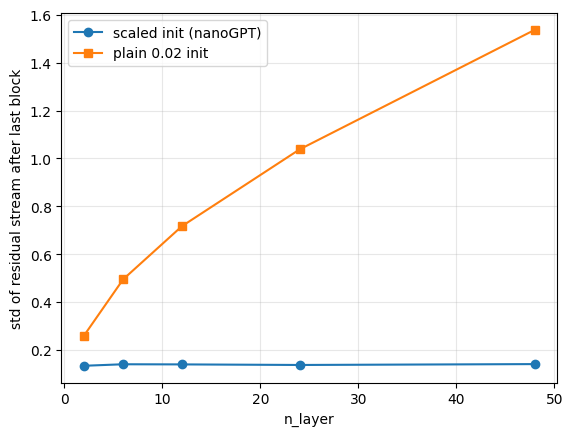

In [19]:
def stream_std(n_layer, scaled):
    cfg = GPTConfig(block_size=64, vocab_size=84, n_layer=n_layer, n_head=6, n_embd=384, dropout=0.0)
    m = GPT(cfg).eval()
    if not scaled:
        for n, p in m.named_parameters():
            if n.endswith('c_proj.weight'): nn.init.normal_(p, 0, 0.02)
    h = m.transformer.wte(torch.randint(0, 84, (2, 64))) + m.transformer.wpe(torch.arange(64))
    for b in m.transformer.h: h = b(h)
    return h.std().item()
Ls = [2, 6, 12, 24, 48]
plt.plot(Ls, [stream_std(L, True) for L in Ls], 'o-', label='scaled init (nanoGPT)')
plt.plot(Ls, [stream_std(L, False) for L in Ls], 's-', label='plain 0.02 init')
plt.xlabel('n_layer'); plt.ylabel('std of residual stream after last block'); plt.legend(); plt.show()

### 🛠 Your turn 5 — assemble `MyGPT` (using your own Block / LayerNorm / Attention / MLP)

In [20]:

class MyGPT(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.config = config
        self.transformer = nn.ModuleDict(dict(
            wte=nn.Embedding(config.vocab_size, config.n_embd),
            wpe=nn.Embedding(config.block_size, config.n_embd),
            drop=nn.Dropout(config.dropout),
            h=nn.ModuleList([MyBlock(config) for _ in range(config.n_layer)]),
            ln_f=MyLayerNorm(config.n_embd, config.bias),
        ))
        self.lm_head = nn.Linear(config.n_embd, config.vocab_size, bias=False)
        self.transformer.wte.weight = self.lm_head.weight          # weight tying
        for m in self.modules():
            if isinstance(m, (nn.Linear, nn.Embedding)):
                nn.init.normal_(m.weight, mean=0.0, std=0.02)
            if isinstance(m, nn.Linear) and m.bias is not None:
                nn.init.zeros_(m.bias)
        for n, p in self.named_parameters():
            if n.endswith('c_proj.weight'):
                nn.init.normal_(p, mean=0.0, std=0.02 / math.sqrt(2 * config.n_layer))

    def forward(self, idx, targets=None):
        b, t = idx.size()
        pos = torch.arange(t, device=idx.device)
        x = self.transformer.drop(self.transformer.wte(idx) + self.transformer.wpe(pos))
        for block in self.transformer.h:
            x = block(x)
        x = self.transformer.ln_f(x)
        if targets is not None:
            logits = self.lm_head(x)
            return logits, F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1), ignore_index=-1)
        return self.lm_head(x[:, [-1], :]), None


In [21]:
def test_gpt():
    cfg = GPTConfig(block_size=16, vocab_size=30, n_layer=3, n_head=2, n_embd=16, dropout=0.0, bias=True)
    ref, mine = GPT(cfg).eval(), MyGPT(cfg).eval()
    assert sum(p.numel() for p in mine.parameters()) == sum(p.numel() for p in ref.parameters()), 'parameter count differs (is weight tying done? any extra params?)'
    load_ref_weights(mine, ref)
    x, y = torch.randint(0, 30, (4, 12)), torch.randint(0, 30, (4, 12))
    (l1, loss1), (l2, loss2) = ref(x, y), mine(x, y)
    close(l2, l1, 'logits with targets'); close(loss2, loss1, 'loss')
    close(mine(x)[0], ref(x)[0], 'inference logits (should be last position only)')
check('MyGPT forward == model.GPT forward', test_gpt)

def test_init():
    cfg = GPTConfig(block_size=64, vocab_size=200, n_layer=8, n_head=4, n_embd=256, dropout=0.0)
    m = MyGPT(cfg)
    assert m.transformer.wte.weight is m.lm_head.weight, 'wte and lm_head must share the same Parameter (weight tying)'
    cp = [p for n, p in m.named_parameters() if n.endswith('c_proj.weight')]
    assert len(cp) == 16, f'expected 16 c_proj weights, found {len(cp)}'
    want = 0.02 / math.sqrt(2 * cfg.n_layer)
    assert all(abs(p.std().item() - want) < 0.15 * want for p in cp), f'c_proj std should be ~{want:.4f}, got {cp[0].std().item():.4f}'
    other = m.transformer.h[0].attn.c_attn.weight
    assert abs(other.std().item() - 0.02) < 0.003, f'other Linear weights should be ~0.02, got {other.std().item():.4f}'
    assert m.transformer.h[0].attn.c_attn.bias.abs().max() == 0, 'biases must start at zero'
    _, loss = m(torch.randint(0, 200, (4, 32)), torch.randint(0, 200, (4, 32)))
    assert abs(loss.item() - math.log(200)) < 0.15, f'initial loss {loss.item():.3f} should be ~ln(200)={math.log(200):.3f}'
check('MyGPT init (tying, scaled c_proj, zero biases, loss≈ln V)', test_init)

number of parameters: 0.01M
✅ MyGPT forward == model.GPT forward


✅ MyGPT init (tying, scaled c_proj, zero biases, loss≈ln V)


### Where do the parameters go?
Change the sizes and watch the split. (Same numbers as the dashboard calculator.)

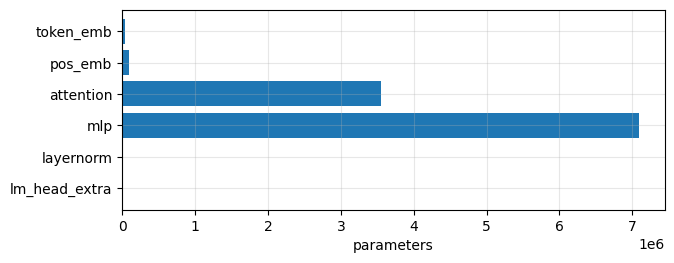

total 10.78M | MLP 66% attention 33% embeddings 1.2% | FLOPs/token (fwd+bwd) 71M | fp32 train state 172 MB
GPT-2 124M:


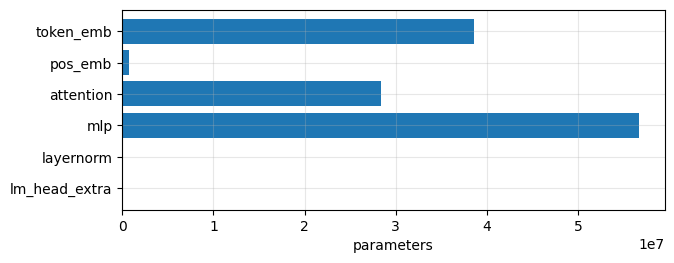

total 124.48M | MLP 46% attention 23% embeddings 31.7% | FLOPs/token (fwd+bwd) 855M | fp32 train state 1992 MB


In [22]:
def show_params(n_layer=6, n_head=6, n_embd=384, block_size=256, vocab=84, tie=True):
    if n_embd % n_head: print('n_embd must be divisible by n_head'); return
    pb = lab.param_breakdown(n_layer, n_head, n_embd, block_size, vocab, True, tie)
    parts = {k: pb[k] for k in ('token_emb', 'pos_emb', 'attention', 'mlp', 'layernorm', 'lm_head_extra')}
    plt.figure(figsize=(7, 2.6)); plt.barh(list(parts)[::-1], list(parts.values())[::-1]); plt.xlabel('parameters'); plt.show()
    print(f"total {pb['total']/1e6:.2f}M | MLP {100*pb['mlp']/pb['total']:.0f}% attention {100*pb['attention']/pb['total']:.0f}% embeddings {100*(pb['token_emb']+pb['pos_emb'])/pb['total']:.1f}% | FLOPs/token (fwd+bwd) {pb['flops_per_token']/1e6:.0f}M | fp32 train state {pb['train_state_mb']:.0f} MB")
show_params()
print('GPT-2 124M:'); show_params(12, 12, 768, 1024, 50304)

In [23]:
W.interact(show_params, n_layer=W.IntSlider(min=1, max=48, value=6), n_head=W.Dropdown(options=[1, 2, 4, 6, 8, 12, 16], value=6), n_embd=W.Dropdown(options=[64, 128, 192, 384, 768, 1024, 1536], value=384),
           block_size=W.Dropdown(options=[64, 256, 1024, 2048], value=256), vocab=W.Dropdown(options=[84, 50304], value=84), tie=W.Checkbox(value=True));

interactive(children=(IntSlider(value=6, description='n_layer', max=48, min=1), Dropdown(description='n_head',…

## 8. Optimiser details
* **AdamW** with **weight decay only on ≥2-D tensors** (matmul weights and embeddings). Biases and LayerNorm gains are 1-D and are not decayed.
* **Learning-rate schedule:** linear warm-up, then cosine decay to `min_lr` (≈ lr/10). Skipping warm-up at lr 3e-3 cost +0.17 val loss in our runs.

### 🛠 Your turn 6 — optimiser groups

In [24]:

def my_configure_optimizers(model, weight_decay, learning_rate, betas):
    params = [p for p in model.parameters() if p.requires_grad]
    decay = [p for p in params if p.dim() >= 2]
    nodecay = [p for p in params if p.dim() < 2]
    groups = [{'params': decay, 'weight_decay': weight_decay}, {'params': nodecay, 'weight_decay': 0.0}]
    return torch.optim.AdamW(groups, lr=learning_rate, betas=betas)


In [25]:
def test_opt():
    m = GPT(cfg_t)
    opt = my_configure_optimizers(m, 0.1, 1e-3, (0.9, 0.99))
    assert isinstance(opt, torch.optim.AdamW), 'return an AdamW'
    g = {x['weight_decay']: x for x in opt.param_groups}
    assert set(g) == {0.1, 0.0}, f'need exactly two groups with weight_decay 0.1 and 0.0, got {sorted(g)}'
    assert all(p.dim() >= 2 for p in g[0.1]['params']) and all(p.dim() < 2 for p in g[0.0]['params']), 'decay group must be the >=2-D tensors'
    assert sum(len(x['params']) for x in opt.param_groups) == len(list(m.parameters())), 'every parameter must be in exactly one group'
check('my_configure_optimizers', test_opt)

number of parameters: 0.01M


✅ my_configure_optimizers


### 🛠 Your turn 7 — learning-rate schedule

In [26]:

def get_lr(it, max_lr, min_lr, warmup_iters, max_iters):
    if it < warmup_iters:
        return max_lr * (it + 1) / (warmup_iters + 1)
    ratio = (it - warmup_iters) / (max_iters - warmup_iters)
    return min_lr + 0.5 * (1 + math.cos(math.pi * ratio)) * (max_lr - min_lr)


✅ get_lr


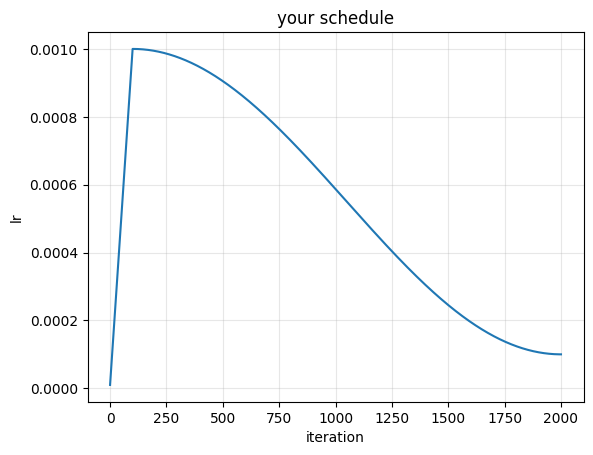

In [27]:
def test_lr():
    f = lambda it: get_lr(it, 1e-3, 1e-4, 100, 2000)
    assert 0 < f(0) < 1e-4, f'lr at it=0 should be tiny but non-zero, got {f(0)}'
    assert abs(f(99) - 1e-3 * 100 / 101) < 1e-9 and abs(f(100) - 1e-3) < 1e-9, 'warm-up should reach max_lr at it=warmup_iters'
    assert abs(f(2000) - 1e-4) < 1e-9, 'should end at min_lr'
    assert abs(f(1050) - (1e-4 + 0.5 * 9e-4)) < 1e-6, 'cosine midpoint should be halfway between max and min'
    assert all(f(i) >= f(i + 1) for i in range(100, 1999)), 'decay phase must be monotone'
check('get_lr', test_lr)
try:
    its = list(range(2001)); plt.plot(its, [get_lr(i, 1e-3, 1e-4, 100, 2000) for i in its]); plt.xlabel('iteration'); plt.ylabel('lr'); plt.title('your schedule'); plt.show()
except NotImplementedError:
    pass

## 9. Sampling
`generate` is a loop: crop to `block_size` → forward → take the **last** position's logits → `/temperature` → (optional top-k) → softmax → sample → append.
* temperature < 1 sharpens (safer, repetitive); > 1 flattens (creative, errors).
* top-k removes the long tail so a rare, wrong character can never be picked.

In [28]:
logits = torch.tensor([3.0, 2.0, 1.0, 0.0, -1.0])
def show_probs(temperature=1.0, top_k=5):
    l = logits / temperature
    if top_k < len(l): l = torch.where(l < torch.topk(l, top_k).values[-1], torch.tensor(-float('inf')), l)
    plt.figure(figsize=(5, 2.4)); plt.bar(range(5), F.softmax(l, -1)); plt.ylim(0, 1); plt.xlabel('token'); plt.ylabel('probability'); plt.show()
W.interact(show_probs, temperature=W.FloatSlider(min=0.1, max=3, step=.1, value=1.0), top_k=W.IntSlider(min=1, max=5, value=5));

interactive(children=(FloatSlider(value=1.0, description='temperature', max=3.0, min=0.1), IntSlider(value=5, …

### 🛠 Your turn 8 — `my_generate`

In [29]:

@torch.no_grad()
def my_generate(model, idx, max_new_tokens, temperature=1.0, top_k=None):
    for _ in range(max_new_tokens):
        idx_cond = idx[:, -model.config.block_size:]
        logits, _ = model(idx_cond)
        logits = logits[:, -1, :] / temperature
        if top_k is not None:
            v, _ = torch.topk(logits, min(top_k, logits.size(-1)))
            logits[logits < v[:, [-1]]] = -float('inf')
        probs = F.softmax(logits, dim=-1)
        idx = torch.cat((idx, torch.multinomial(probs, num_samples=1)), dim=1)
    return idx


In [30]:
def test_gen():
    m = GPT(cfg_t).eval()
    idx = torch.randint(0, 30, (2, 4))
    torch.manual_seed(0); a = m.generate(idx.clone(), 40, temperature=0.8, top_k=5)       # 40 > block_size=16, tests cropping too
    torch.manual_seed(0); b = my_generate(m, idx.clone(), 40, temperature=0.8, top_k=5)
    assert a.shape == b.shape, f'shape {tuple(b.shape)} vs {tuple(a.shape)}'
    assert torch.equal(a, b), 'with the same seed your samples must equal model.generate (same order of ops: /temperature, then top-k, then softmax)'
check('my_generate == model.generate (same seed)', test_gen)

number of parameters: 0.01M
✅ my_generate == model.generate (same seed)


### 🔎 Play with the trained model

In [31]:
def play(prompt='ROMEO.\n', temperature=0.8, top_k=40, n=400, seed=0):
    print(lab.generate_text(model_ref, meta, prompt, n, temperature, top_k, seed))
play()

ROMEO.
Be married.

COMINIUS.
No, my lord,
Thou wilt be a fool.

FIRST CITIZEN.
I to the content of your mind. The courtesy
To slink it unto the other Mark Antony
Caesar and the second double of her gold,
Bespend to the hand, and to swear and her strength,--
You have so arrant well to see it with hair;
And now, this shall we are gone, and truth
Is a secure of her heart: it is not yet
A flower that which 


In [32]:
W.interact_manual(play, prompt=W.Textarea(value='ROMEO.\n', layout=W.Layout(width='400px')), temperature=W.FloatSlider(min=0.1, max=2.0, step=.1, value=0.8),
                  top_k=W.IntSlider(min=0, max=84, value=40), n=W.IntSlider(min=50, max=1000, step=50, value=400), seed=W.IntSlider(min=0, max=99, value=0));

interactive(children=(Textarea(value='ROMEO.\n', description='prompt', layout=Layout(width='400px')), FloatSli…

In [33]:
text = 'To be, or not to b'
print(f'next-character distribution after {text!r}:')
for ch, p in lab.next_char_probs(model_ref, meta, text): print(f'  {ch:6s} {p:.3f}  ' + '█' * int(p * 50))

next-character distribution after 'To be, or not to b':
  'e'    0.914  █████████████████████████████████████████████
  'r'    0.036  █
  'u'    0.016  
  'l'    0.011  
  'o'    0.009  
  'i'    0.007  
  'a'    0.005  
  'y'    0.001  


## 10. 🧪 Experiments — see what each technique buys

### 10a. The 40 saved runs (2000 iters each, A100)
Pick runs to compare. Baseline val loss is 1.397 (seed noise ±0.003).

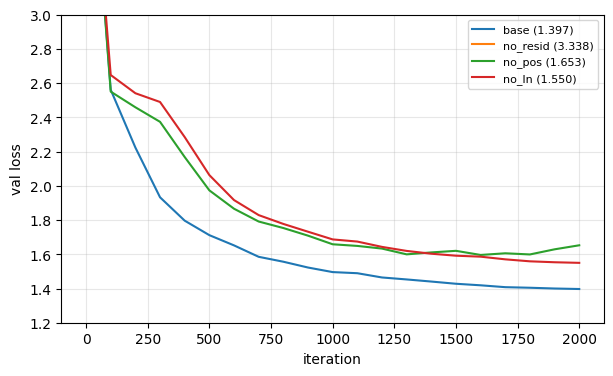

,run,params_M,train,val,delta_vs_base,best_val,iters,seconds
0,no_causal,10.68,0.010,0.010,-1.387,0.010,2000,67
1,long_drop_0.2,10.68,1.008,1.275,-0.122,1.275,8000,212
2,ckpt_base,10.68,1.158,1.350,-0.047,1.350,3000,94
3,drop_0,10.68,1.100,1.360,-0.037,1.360,2000,60
4,width_768,42.59,1.172,1.361,-0.036,1.355,2000,118
5,layers_12,21.33,1.184,1.368,-0.029,1.368,2000,108
6,layers_8,14.23,1.214,1.375,-0.022,1.375,2000,81
7,heads_12,10.68,1.223,1.382,-0.015,1.382,2000,64
8,act_relu,10.68,1.239,1.387,-0.010,1.387,2000,67
9,base_s2,10.68,1.239,1.395,-0.002,1.395,2000,64


In [34]:
R = lab.load_results()
def plot_runs(runs=('base', 'no_resid', 'no_pos', 'no_ln'), metric='val', ymax=3.0):
    plt.figure(figsize=(7, 4))
    for n in runs: plt.plot(R[n]['steps'], R[n][metric], label=f"{n} ({R[n]['final_val']:.3f})")
    plt.ylim(1.2, ymax); plt.xlabel('iteration'); plt.ylabel(f'{metric} loss'); plt.legend(fontsize=8); plt.show()
plot_runs()
display(lab.results_frame().head(12))

In [35]:
W.interact(plot_runs, runs=W.SelectMultiple(options=sorted(R), value=('base', 'no_pos'), rows=12), metric=['val', 'train'], ymax=W.FloatSlider(min=1.5, max=4, value=3.0));

interactive(children=(SelectMultiple(description='runs', index=(2, 34), options=('act_none', 'act_relu', 'base…

### 10b. Run your own, live (≈10 s each on the A100)
**Predict first.** For each variant below, write down: will it train? roughly how far from `base` after 300 steps?

base       val after 300 its: 2.035


no_resid   val after 300 its: 3.337


no_pos     val after 300 its: 2.346


no_ln      val after 300 its: 2.492


no_mlp     val after 300 its: 2.443


heads_1    val after 300 its: 1.987


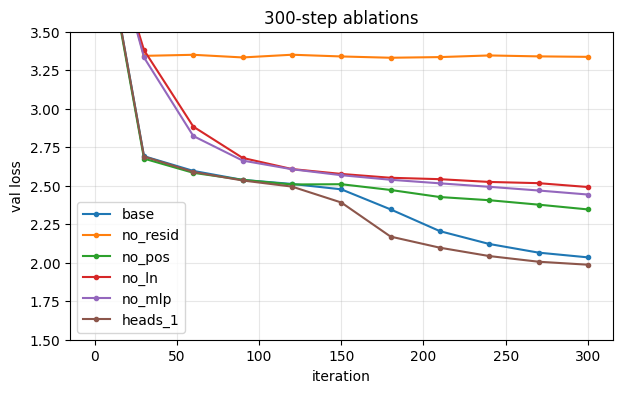

In [36]:
VARIANTS = {'base': {}, 'no_resid': dict(residual=False), 'no_pos': dict(pos_emb=False), 'no_ln': dict(layernorm=False), 'no_mlp': dict(mlp=False), 'heads_1': dict(n_head=1)}
live = {}
for name, kw in VARIANTS.items():
    live[name] = lab.quick_run(name, iters=300, **kw)
    print(f"{name:10s} val after 300 its: {live[name]['val'][-1]:.3f}")
plt.figure(figsize=(7, 4))
for n, r in live.items(): plt.plot(r['steps'], r['val'], marker='o', ms=3, label=n)
plt.ylim(1.5, 3.5); plt.xlabel('iteration'); plt.ylabel('val loss'); plt.legend(); plt.title('300-step ablations'); plt.show()

**Your own variants.** Any `Cfg` field (`n_layer`, `n_head`, `n_embd`, `block_size`, `dropout`, `bias`, `pos_emb`, `residual`, `layernorm`, `causal`, `attn`, `mlp`, `activation`, `tie_weights`, `scaled_init`, `attn_scale`) or hyper-parameter (`lr`, `iters`, `warmup`, `wd`, `batch_size`, `schedule=constant`, `seed`) works:

final val 2.56


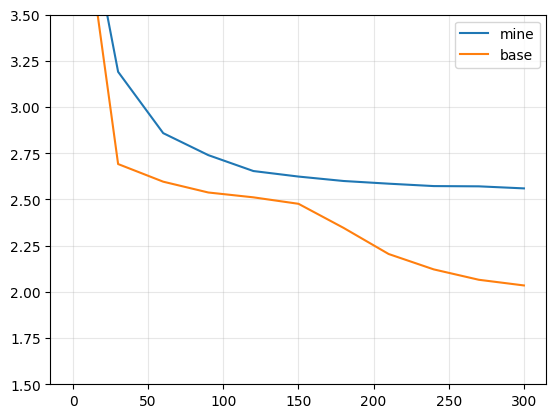

In [37]:
mine = lab.quick_run('mine', iters=300, n_layer=2, lr=3e-3, warmup=0)       # <- edit me
print('final val', mine['val'][-1]); plt.plot(mine['steps'], mine['val'], label='mine'); plt.plot(live['base']['steps'], live['base']['val'], label='base'); plt.ylim(1.5, 3.5); plt.legend(); plt.show()

**Questions to answer with experiments** (use `lab.quick_run`, or the full `run_experiment.py`):
1. `causal=False` gives a validation loss near 0. Why is that a *bug*, not a success? (Try generating from such a model.)
2. At which learning rate does training become unstable for 300 steps? Does warm-up fix it?
3. With dropout 0, when does validation loss start to rise? (Use `iters=3000`, `dropout=0.0`, look at train vs val.)
4. Does `tie_weights=False` or `scaled_init=False` matter at `n_layer=2`? At `n_layer=12`? Why might the answer change?

## 11. Capstone: train **your** GPT
Everything you wrote (`MyGPT` + `get_lr` + `my_configure_optimizers`) now trains on Shakespeare. A small model on the GPU, 400 steps (< 1 min).

it    0 loss 4.449  (0s)


it  100 loss 2.520  (2s)


it  200 loss 2.461  (4s)


it  300 loss 2.350  (6s)


it  400 loss 2.275  (8s)
number of parameters: 0.80M
it    0 loss 4.449  (0s)


it  100 loss 2.520  (1s)


it  200 loss 2.461  (2s)


it  300 loss 2.350  (4s)


it  400 loss 2.274  (5s)


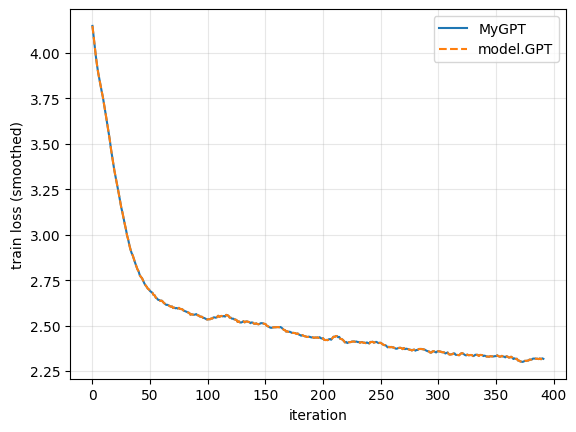

your model:



BEMANTHN.

He  MEROUTHONNTN.
A fend veved, ra fare dove thear, tou ient and o then ba mouting mave,
Wot the couct ser bealice iou thtat wo sus with theen, dof send
me thalle len toull be fofe I--
Whet pench I the hat and foton wind reat benet.

HOfow, be ther mexeary Ror thit wo he Gow'd wouaith nos


In [38]:
def train_mine(Model=None, iters=400, batch_size=32, lr=1e-3):
    cfg = GPTConfig(block_size=128, vocab_size=len(meta['itos']), n_layer=4, n_head=4, n_embd=128, dropout=0.0, bias=False)
    torch.manual_seed(0)
    m = Model(cfg).to(device)
    opt = my_configure_optimizers(m, 0.1, lr, (0.9, 0.99))
    hist = []
    t0 = time.time()
    for it in range(iters + 1):
        for g in opt.param_groups: g['lr'] = get_lr(it, lr, lr / 10, 50, iters)
        x, y = get_batch('train', batch_size, cfg.block_size)
        with torch.autocast(device, dtype=torch.bfloat16, enabled=device == 'cuda'):
            _, loss = m(x, y)
        loss.backward(); torch.nn.utils.clip_grad_norm_(m.parameters(), 1.0); opt.step(); opt.zero_grad(set_to_none=True)
        hist.append(loss.item())
        if it % 100 == 0: print(f'it {it:4d} loss {loss.item():.3f}  ({time.time()-t0:.0f}s)')
    return m, hist, cfg
try:
    my_model, hist_mine, cfg_c = train_mine(MyGPT)
    _, hist_ref, _ = train_mine(GPT)
    plt.plot(np.convolve(hist_mine, np.ones(10) / 10, 'valid'), label='MyGPT'); plt.plot(np.convolve(hist_ref, np.ones(10) / 10, 'valid'), '--', label='model.GPT')
    plt.xlabel('iteration'); plt.ylabel('train loss (smoothed)'); plt.legend(); plt.show()
    print('your model:'); idx0 = torch.tensor([[meta['stoi']['\n']]], device=device)
    print(lab.decode(meta, my_generate(my_model.eval(), idx0, 300, 0.8, 40)[0].tolist()))
except NotImplementedError:
    print('⏳ finish exercises 1-8 first, then come back here to train your own model.')

## 12. Where to go next (no solutions provided, that's the point)
1. **Rotary position embeddings** instead of `wpe`; compare val loss and *context-length extrapolation* (train at 128, test at 256).
2. **RMSNorm** instead of LayerNorm; **SwiGLU** instead of GELU MLP (what happens to the 4× expansion if you want equal parameters?).
3. **Grouped-query attention:** share K/V across heads. Measure memory in `generate`.
4. **KV cache** for `generate`: avoid recomputing the prefix. Verify identical samples, measure speed-up.
5. Re-run the ablation table on a *different* dataset (BPE tokens, OpenWebText sample) and see which effects change.
6. Find the largest `n_layer` where scaled-init off still trains; plot instability vs depth.

You have now read, run, broken, and rebuilt `model.py`. 🎉